In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import glob, h5py

In [2]:
# Load dataset
file_path = "/content/107l003p143_spikes.mat"  # If running inside dataset/experiments/

with h5py.File(file_path, "r") as f:
    # Read stimulus orientations (1 to 8)
    stim = np.array(f["stim"]).squeeze().astype(int)  # Shape: (3200,)

    # Read V1 and V2 spike trains
    ref_spikes = f["spikes"]
    v1_spikes = np.array(f[ref_spikes[0, 0]])  # Shape: (3200, 1280, 111)
    v2_spikes = np.array(f[ref_spikes[1, 0]])  # Shape: (3200, 1280, 37)

print(f"Stimulus shape: {stim.shape}, unique orientations: {np.unique(stim)}")
print(f"V1 spike shape: {v1_spikes.shape} (trials, ms, neurons)")
print(f"V2 spike shape: {v2_spikes.shape} (trials, ms, neurons)")

Stimulus shape: (3200,), unique orientations: [1 2 3 4 5 6 7 8]
V1 spike shape: (3200, 1280, 111) (trials, ms, neurons)
V2 spike shape: (3200, 1280, 37) (trials, ms, neurons)


In [ ]:
trials_ori_1 = np.where(stim == 8)[0]
print((trials_ori_1))

[   6   11   19   25   38   43   49   63   71   79   85   93   98  106
  114  122  130  143  148  156  164  169  176  187  195  200  210  216
  230  238  242  250  263  271  272  284  292  300  310  318  326  328
  339  347  355  364  372  376  388  396  404  409  417  430  438  444
  451  462  466  478  480  494  502  510  517  521  532  540  548  556
  566  574  582  590  592  603  615  623  626  632  642  649  657  670
  678  683  688  702  711  712  725  733  736  750  758  760  771  779
  790  799  804  812  820  829  833  847  853  861  869  877  885  893
  901  911  919  927  929  942  950  952  965  971  981  985  993 1007
 1008 1022 1030 1038 1046 1053 1061 1069 1077 1081 1089 1096 1104 1118
 1126 1129 1137 1146 1153 1166 1171 1179 1188 1198 1203 1211 1223 1231
 1239 1247 1255 1263 1271 1273 1282 1290 1298 1309 1318 1326 1334 1342
 1344 1358 1366 1374 1382 1388 1393 1402 1410 1419 1431 1438 1447 1455
 1456 1469 1477 1485 1493 1502 1506 1514 1520 1534 1542 1544 1555 1560
 1571 

Question 1:  How many neurons are recorded in the session you selected?

In [3]:
neuron_V1 = v1_spikes.shape[-1]
neuron_V2 = v2_spikes.shape[-1]

print(f"V1 neurons: {neuron_V1} neurons")
print(f"V2 neurons: {neuron_V2} neurons")
#print(v2_spikes.shape[-1])

V1 neurons: 111 neurons
V2 neurons: 37 neurons


 Question 2:How many trials were presented for each orientation?

In [4]:
unique_orienttations = np.unique(stim)
for i in unique_orienttations:
  print(f"There are  {len(np.where(stim == i )[0])} trials in the {i}th orientation")

There are  400 trials in the 1th orientation
There are  400 trials in the 2th orientation
There are  400 trials in the 3th orientation
There are  400 trials in the 4th orientation
There are  400 trials in the 5th orientation
There are  400 trials in the 6th orientation
There are  400 trials in the 7th orientation
There are  400 trials in the 8th orientation


Question 3: What are the stimulus orientations?

In [5]:
# Convert to 0-indexed values (0 to 7)
ori_idx = stim - 1

# Option A: 8 orientations across 180° (step of 22.5°)
ori_angles_180 = ori_idx * (180.0 / 8)  # [0°, 22.5°, 45°, 67.5°, 90°, 112.5°, 135°, 157.5°]
print(f" The stimulus orientatons are {np.unique(ori_angles_180)} ")


 The stimulus orientatons are [  0.   22.5  45.   67.5  90.  112.5 135.  157.5] 


Question 4: Plot the mean orientation tuning curve for several neurons.


In [6]:
v1_spikes.shape

(3200, 1280, 111)

In [7]:
# Select 6 example neurons to plot from V1
neuron_ids = [0, 2, 3, 4, 7, 9]
selected_v1_spikes = v1_spikes[:, :, neuron_ids]
selected_v1_spikes.shape

v1_counts = np.sum(selected_v1_spikes, axis=1)  # shape: (3200 trials, 6 neurons)
v1_counts.shape
# # Convert spike counts to firing rate in Hz
# v1_rates = v1_counts / 1.18

(3200, 6)

In [8]:
# 2. Compute Mean and SEM across the 8 orientations
orientations = np.arange(1, 9)
angles_deg = (orientations - 1) * 45  # [0°, 45°, 90°, ..., 315°]
mean_rates = np.zeros((8, len(neuron_ids)))
sem_rates = np.zeros((8, len(neuron_ids)))
for i, ori in enumerate(orientations):
    mask = (stim == ori)  # 400 trials per orientation
    mean_rates[i] = np.mean(v1_rates[mask], axis=0)
    sem_rates[i] = np.std(v1_rates[mask], axis=0) / np.sqrt(np.sum(mask))
# 3. Multi-Panel Cartesian Plot
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
axes = axes.flatten()
for idx, n_id in enumerate(neuron_ids):
    ax = axes[idx]
    ax.errorbar(
        angles_deg,
        mean_rates[:, idx],
        yerr=sem_rates[:, idx],
        fmt="-o",
        color="#1f77b4",
        ecolor="#9ecae1",
        capsize=4,
        linewidth=2,
        markersize=6
    )
    ax.set_title(f"V1 Neuron {n_id}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
    ax.set_xticks(angles_deg)
    ax.grid(True, linestyle="--", alpha=0.5)
for ax in axes[3:]:
    ax.set_xlabel("Orientation Angle (degrees)", fontsize=11)
plt.suptitle("Mean Orientation Tuning Curves (Mean ± SEM, N=400 trials)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

NameError: name 'v1_rates' is not defined

In [ ]:
# # Plot firing rate
# plt.plot(ori_angles_180[0], firing_rate[0])

# plt.xlabel("Time (s)")
# plt.ylabel("Firing rate (Hz)")
# plt.title("Estimated Firing Rate from Spike Times")
# plt.show()

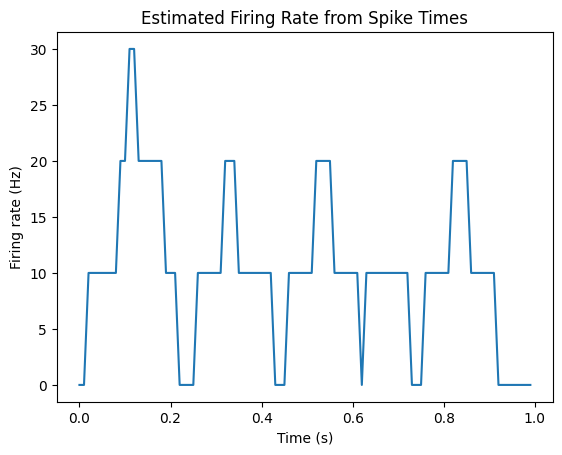

In [ ]:
# Simulated spike times (seconds)
spikes = np.array([
    0.12, 0.18, 0.21, 0.35, 0.42,
    0.55, 0.61, 0.72, 0.85, 0.91
])

# Sliding window
dt = 0.1  # 100 ms

# Time points at which we calculate firing rate
time = np.arange(0, 1, 0.01)

# Calculate firing rate
firing_rate = []

for t in time:
    count = np.sum((spikes >= t) & (spikes < t + dt))
    rate = count / dt
    firing_rate.append(rate)

# Plot firing rate
plt.plot(time, firing_rate)

plt.xlabel("Time (s)")
plt.ylabel("Firing rate (Hz)")
plt.title("Estimated Firing Rate from Spike Times")
plt.show()

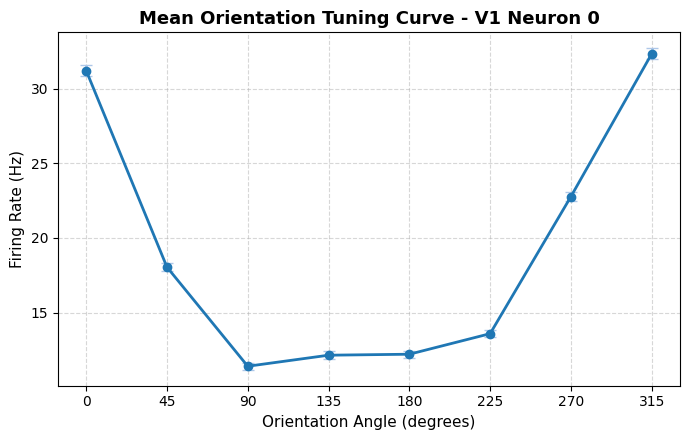

In [9]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# 1. Configuration
file_path = "107l003p143_spikes.mat"
neuron_id = 0  # Index of the neuron you want to plot (e.g. 0 to 158 for V1)

# 2. Load Data
with h5py.File(file_path, "r") as f:
    stim = np.array(f["stim"]).squeeze().astype(int)  # Orientation condition (1 to 8)
    v1_ref = f["spikes"][0, 0]

    # Extract spikes for this one neuron during the stimulus window (100 ms to 1280 ms)
    # 1180 ms duration = 1.18 seconds
    spikes = f[v1_ref][:, 100:, neuron_id]  # Shape: (3200 trials, 1180 ms)
    spike_counts = np.sum(spikes, axis=1)    # Total spikes per trial

# Convert to firing rate in Hz (spikes per second)
firing_rates = spike_counts / 1.18

# 3. Compute Mean and SEM for each of the 8 orientations
orientations = np.arange(1, 9)
angles_deg = (orientations - 1) * 45  # [0°, 45°, 90°, 135°, 180°, 225°, 270°, 315°]

mean_rates = []
sem_rates = []

for ori in orientations:
    rates_ori = firing_rates[stim == ori]  # 400 trials for this orientation
    mean_rates.append(np.mean(rates_ori))
    sem_rates.append(np.std(rates_ori) / np.sqrt(len(rates_ori)))

# 4. Plot the Tuning Curve
plt.figure(figsize=(7, 4.5))
plt.errorbar(
    angles_deg,
    mean_rates,
    yerr=sem_rates,
    fmt="-o",
    color="#1f77b4",
    ecolor="#aec7e8",
    capsize=4,
    elinewidth=2,
    linewidth=2,
    markersize=6
)

plt.title(f"Mean Orientation Tuning Curve - V1 Neuron {neuron_id}", fontsize=13, fontweight="bold")
plt.xlabel("Orientation Angle (degrees)", fontsize=11)
plt.ylabel("Firing Rate (Hz)", fontsize=11)
plt.xticks(angles_deg)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Spike shape: (3200, 1280, 111)
Orientation angles: [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]

Neuron ranking:
 neuron  preferred_orientation_deg  best_tested_orientation_deg  OSI_vector  OSI_preferred_orthogonal  mean_firing_rate_Hz
     89                     93.983                         90.0       0.813                     0.981                3.511
     81                    155.167                        157.5       0.548                     0.853               27.490
     22                    134.359                        135.0       0.505                     0.771                3.717
     34                    139.595                        135.0       0.504                     0.829                3.103
     93                    128.820                        135.0       0.465                     0.777                5.079
     90                     97.252                         90.0       0.462                     0.731               13.500
      2              

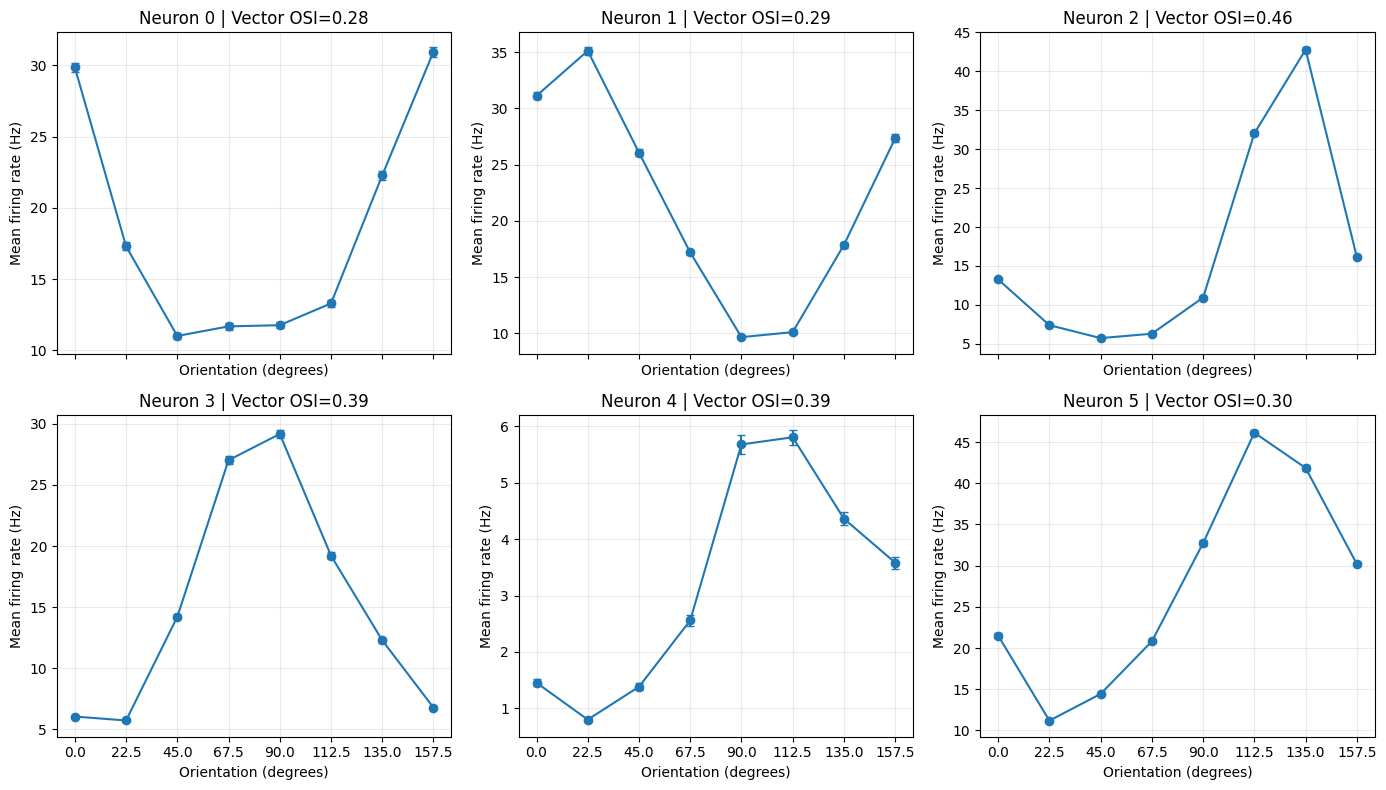

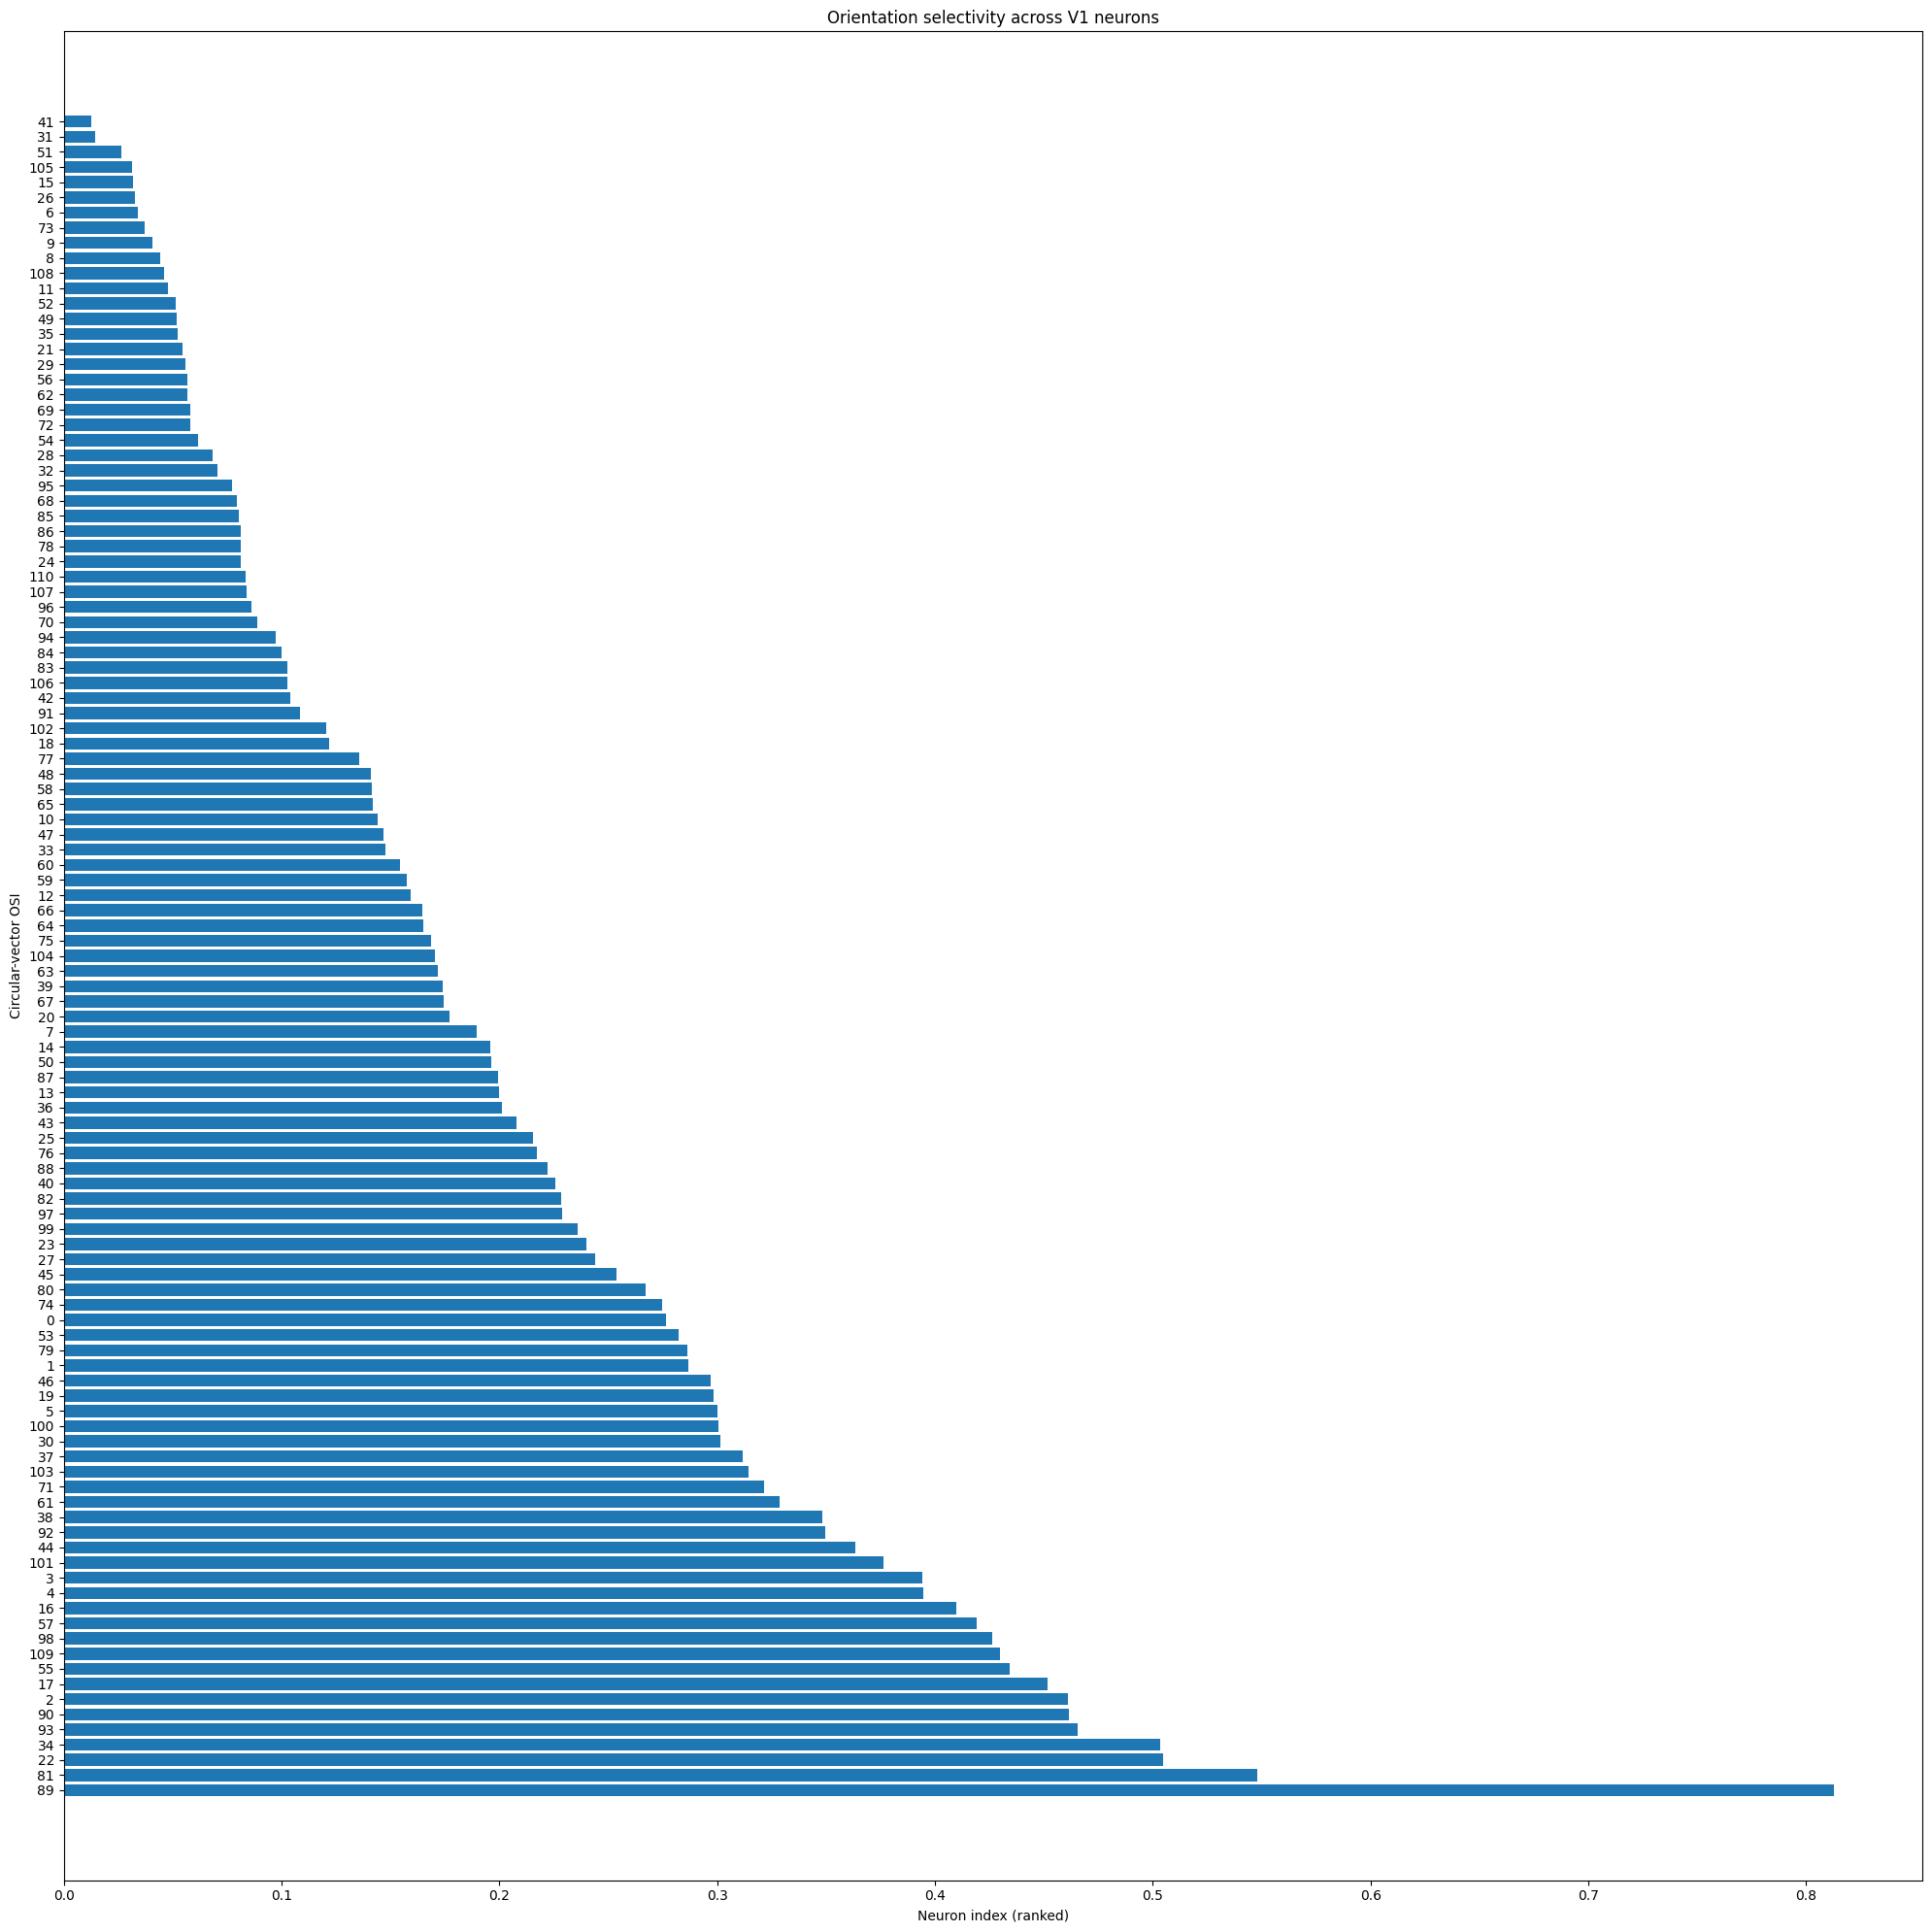

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------
spikes = np.asarray(v1_spikes)
stim_values = np.asarray(stim).flatten()

n_trials, n_time, n_neurons = spikes.shape

# Convert stimulus labels 1-8 to angles 0-157.5 degrees
ori_idx = stim_values - 1
ori_angles = ori_idx * (180.0 / 8)

orientations = np.sort(np.unique(ori_angles))

print("Spike shape:", spikes.shape)
print("Orientation angles:", orientations)

# --------------------------------------------------
# 2. Calculate firing rate for each trial
# --------------------------------------------------
# Assumes 1 ms bins
trial_rates = spikes.sum(axis=1) / (n_time / 1000)

# Mean response for each orientation and neuron
mean_rates = np.array([
    trial_rates[ori_angles == angle].mean(axis=0)
    for angle in orientations
])

# --------------------------------------------------
# 3. Calculate circular-vector OSI
# --------------------------------------------------
theta = np.deg2rad(2 * orientations)

weights = np.maximum(mean_rates, 0)

vectors = np.sum(
    weights * np.exp(1j * theta[:, None]),
    axis=0
)

total_response = weights.sum(axis=0)

osi_vector = np.divide(
    np.abs(vectors),
    total_response,
    out=np.zeros(n_neurons),
    where=total_response > 0
)

preferred_orientation = (
    np.rad2deg(np.angle(vectors)) / 2
) % 180

# --------------------------------------------------
# 4. Calculate preferred-versus-orthogonal OSI
# --------------------------------------------------
osi_orthogonal = np.full(n_neurons, np.nan)
preferred_stimulus = np.full(n_neurons, np.nan)

for neuron in range(n_neurons):

    # Strongest observed response
    pref_idx = np.argmax(mean_rates[:, neuron])
    pref_angle = orientations[pref_idx]
    preferred_stimulus[neuron] = pref_angle

    # Axial distance from preferred orientation
    angular_distance = np.abs(
        ((orientations - pref_angle + 90) % 180) - 90
    )

    # Select orientation 90 degrees away
    orth_idx = np.argmin(np.abs(angular_distance - 90))

    r_pref = mean_rates[pref_idx, neuron]
    r_orth = mean_rates[orth_idx, neuron]

    denominator = r_pref + r_orth

    if denominator > 0:
        osi_orthogonal[neuron] = (
            (r_pref - r_orth) / denominator
        )

# --------------------------------------------------
# 5. Rank neurons
# --------------------------------------------------
results = pd.DataFrame({
    "neuron": np.arange(n_neurons),
    "preferred_orientation_deg": preferred_orientation,
    "best_tested_orientation_deg": preferred_stimulus,
    "OSI_vector": osi_vector,
    "OSI_preferred_orthogonal": osi_orthogonal,
    "mean_firing_rate_Hz": trial_rates.mean(axis=0)
})

results = results.sort_values(
    "OSI_vector", ascending=False
).reset_index(drop=True)

print("\nNeuron ranking:")
print(results.round(3).to_string(index=False))

# --------------------------------------------------
# 6. Plot all neuron tuning curves
# --------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
axes = axes.flatten()

for neuron, ax in enumerate(axes):

    rates = mean_rates[:, neuron]

    sems = np.array([
        trial_rates[ori_angles == angle, neuron].std(ddof=1)
        / np.sqrt(np.sum(ori_angles == angle))
        for angle in orientations
    ])

    ax.errorbar(
        orientations, rates, yerr=sems,
        fmt="o-", capsize=3
    )

    ax.set_title(
        f"Neuron {neuron} | Vector OSI={osi_vector[neuron]:.2f}"
    )
    ax.set_xlabel("Orientation (degrees)")
    ax.set_ylabel("Mean firing rate (Hz)")
    ax.set_xticks(orientations)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Plot ranking by vector OSI
# --------------------------------------------------
plt.figure(figsize=(20, 20))

plt.barh(
    results["neuron"].astype(str),
    results["OSI_vector"]
)

plt.xlabel("Neuron index (ranked)")
plt.ylabel("Circular-vector OSI")
plt.title("Orientation selectivity across V1 neurons")
plt.tight_layout()
plt.show()


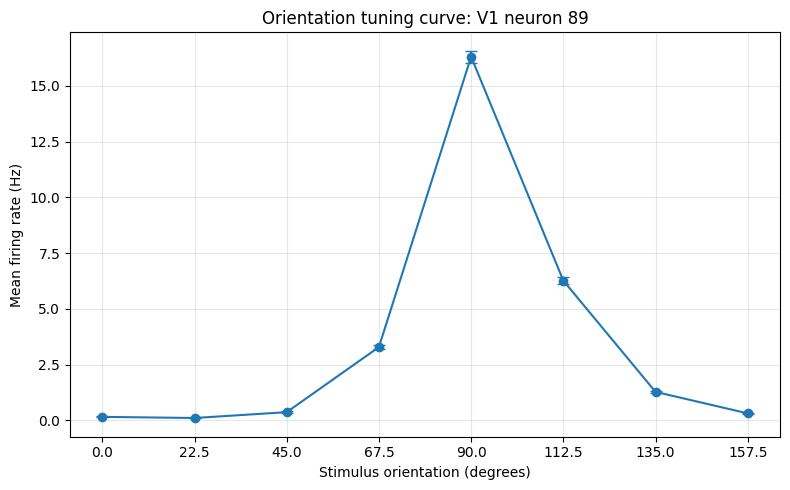

In [11]:
import matplotlib.pyplot as plt
import numpy as np

neuron = 89

rates = mean_rates[:, neuron]

sems = np.array([
    trial_rates[ori_angles == angle, neuron].std(ddof=1)
    / np.sqrt(np.sum(ori_angles == angle))
    for angle in orientations
])

plt.figure(figsize=(8, 5))
plt.errorbar(
    orientations, rates, yerr=sems,
    fmt="o-", capsize=4
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (Hz)")
plt.title("Orientation tuning curve: V1 neuron 89")
plt.xticks(orientations)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Question 5: Select one neuron for the remainder of the assignment.


Neuron 89 is chosen

## Polynomial Regression Models for Neuronal Orientation Tuning

We will first attempt to describe the neuron's response using polynomial regression. We will fit four models:

**Model 1: Linear**

$$
f(\theta) = \beta_0 + \beta_1\theta
$$

**Model 2: Third-order polynomial**

$$
f(\theta) = \beta_0 + \beta_1\theta + \beta_2\theta^2 + \beta_3\theta^3
$$

**Model 3: Fouth-order polynomial**

$$
f(\theta) = \beta_0 + \beta_1\theta + \beta_2\theta^2
+ \beta_3\theta^3 + \beta_4\theta^4
$$

**Model 4: Seventh-order polynomial**

$$
\begin{aligned}
f(\theta) ={}& \beta_0 + \beta_1\theta + \beta_2\theta^2
+ \beta_3\theta^3 + \beta_4\theta^4 \\
&+ \beta_5\theta^5 + \beta_6\theta^6 + \beta_7\theta^7
\end{aligned}
$$

Here, $\theta$ represents the stimulus orientation, $f(\theta)$ represents the neuron's predicted response, and $\beta_0, \beta_1, \ldots, \beta_n$ are the regression coefficients estimated from the data.

We will compare the four models to determine how well each captures the neuron's orientation tuning.

In [ ]:
print(mean_rates)

[[31.20338983 13.88983051  6.16949153  1.44279661 45.34322034 17.11864407]
 [18.04237288  7.58686441  5.76694915  0.76271186 59.21398305 18.62288136]
 [11.40466102  5.76271186 14.15889831  1.3559322  78.96822034 20.40042373]
 [12.1440678   6.37711864 27.35169492  2.56991525 75.81567797 18.32415254]
 [12.20974576 11.19915254 29.38559322  5.81355932 48.05508475 16.13983051]
 [13.58686441 33.22669492 19.20127119  5.87923729 38.26271186 16.72669492]
 [22.76694915 44.37288136 12.3220339   4.38771186 37.37923729 17.375     ]
 [32.33262712 16.58898305  6.75635593  3.69279661 44.75635593 17.83050847]]


Neuron: 89
Training trials: 2560
Test trials: 640
Slope: 0.0197
Intercept: 2.0629
Test R²: 0.0322
Test RMSE: 5.0657 Hz


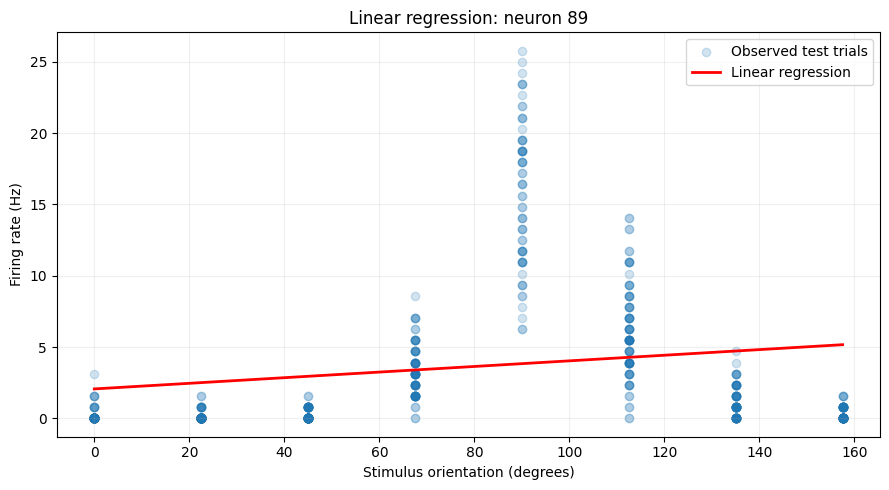

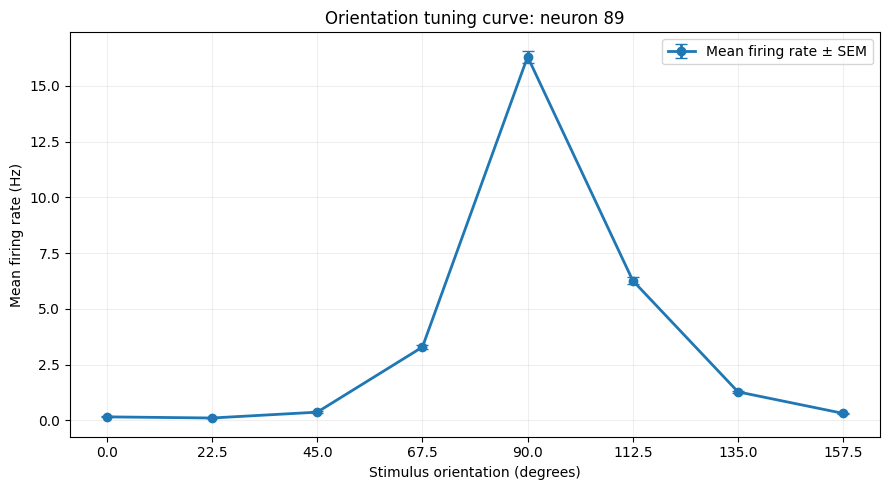

In [12]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# ==========================================
# 1. Select neuron
# ==========================================
neuron = 89

# ==========================================
# 2. Convert stimulus labels to orientations
# Labels 1-8 correspond to 0, 22.5, ..., 157.5 degrees
# ==========================================
angles = (np.asarray(stim).flatten() - 1) * 22.5

# ==========================================
# 3. Extract firing rate for each trial
# v1_spikes shape: (trials, time, neurons)
# ==========================================
spikes = np.asarray(v1_spikes)

# Check that stimulus and spike data match
assert len(angles) == spikes.shape[0], (
    "Number of stimulus labels does not match number of trials."
)

assert 0 <= neuron < spikes.shape[2], (
    "Neuron index is outside the available range."
)

# Calculate trial duration in seconds
duration_sec = spikes.shape[1] / 1000

# Total spikes per trial divided by duration
y = spikes[:, :, neuron].sum(axis=1) / duration_sec

# One predictor: stimulus orientation
X = angles.reshape(-1, 1)

# ==========================================
# 4. Split into training and test sets
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# ==========================================
# 5. Fit linear regression
# ==========================================
model = LinearRegression()
model.fit(X_train, y_train)

# Predict firing rates for held-out trials
y_pred = model.predict(X_test)

# ==========================================
# 6. Evaluate model
# ==========================================
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Neuron: {neuron}")
print(f"Training trials: {len(X_train)}")
print(f"Test trials: {len(X_test)}")
print(f"Slope: {model.coef_[0]:.4f}")
print(f"Intercept: {model.intercept_:.4f}")
print(f"Test R²: {r2:.4f}")
print(f"Test RMSE: {rmse:.4f} Hz")

# ==========================================
# 7. Plot observed test trials and regression line
# ==========================================
plt.figure(figsize=(9, 5))

plt.scatter(
    X_test.ravel(),
    y_test,
    alpha=0.2,
    label="Observed test trials"
)

# Generate a smooth line across the orientation range
X_line = np.linspace(0, 157.5, 200).reshape(-1, 1)
y_line = model.predict(X_line)

plt.plot(
    X_line.ravel(),
    y_line,
    color="red",
    linewidth=2,
    label="Linear regression"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Firing rate (Hz)")
plt.title(f"Linear regression: neuron {neuron}")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ==========================================
# 8. Plot mean firing rate at each orientation
# ==========================================
unique_angles = np.sort(np.unique(angles))

mean_rates = np.array([
    y[angles == angle].mean()
    for angle in unique_angles
])

std_rates = np.array([
    y[angles == angle].std()
    for angle in unique_angles
])

trial_counts = np.array([
    np.sum(angles == angle)
    for angle in unique_angles
])

# Standard error of the mean
sem_rates = std_rates / np.sqrt(trial_counts)

plt.figure(figsize=(9, 5))

plt.errorbar(
    unique_angles,
    mean_rates,
    yerr=sem_rates,
    fmt="o-",
    capsize=4,
    linewidth=2,
    markersize=6,
    label="Mean firing rate ± SEM"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (Hz)")
plt.title(f"Orientation tuning curve: neuron {neuron}")
plt.xticks(unique_angles)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Neuron: 89
Training trials: 2560
Test trials: 640

Model         Features     Test R2      Test RMSE
-------------------------------------------------
Degree 1             1      0.0322         5.0657
Degree 3             3      0.4081         3.9615
Degree 4             4      0.5213         3.5627
Degree 7             7      0.8263         2.1460


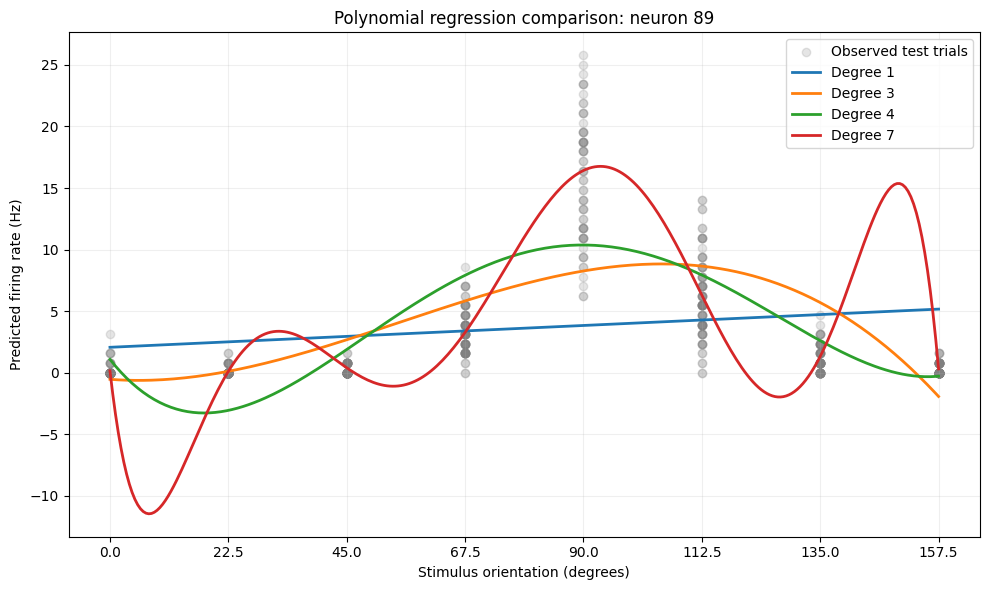

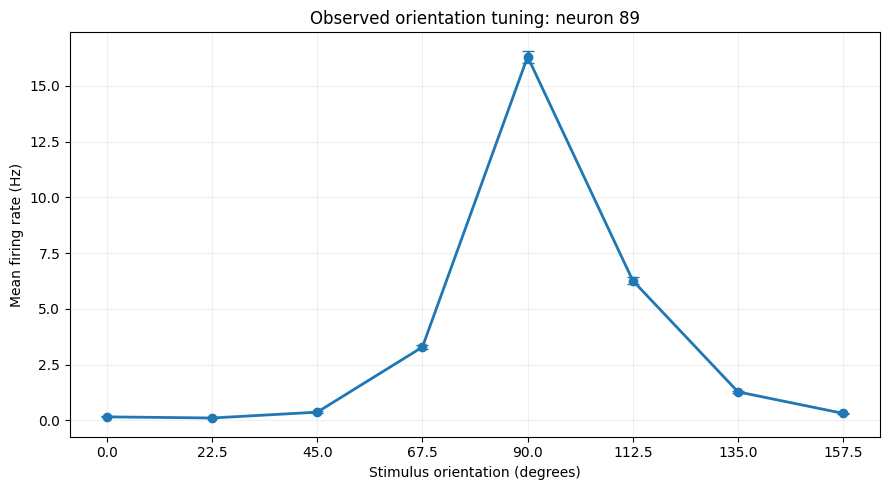

In [13]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# ==========================================
# 1. Select neuron and prepare the data
# ==========================================
neuron = 89

# Convert stimulus labels 1-8 to orientations:
# 0, 22.5, 45, 67.5, 90, 112.5, 135, 157.5 degrees
angles = (np.asarray(stim).flatten() - 1) * 22.5

# Spike data shape: (trials, time, neurons)
spikes = np.asarray(v1_spikes)

assert len(angles) == spikes.shape[0], (
    "Stimulus labels and spike trials do not match."
)
assert 0 <= neuron < spikes.shape[2], (
    "Invalid neuron index."
)

# Convert spike counts to firing rate in Hz
duration_sec = spikes.shape[1] / 1000
y = spikes[:, :, neuron].sum(axis=1) / duration_sec

# Original feature: orientation
X = angles.reshape(-1, 1)

# ==========================================
# 2. Scale orientation values
# ==========================================
# Map angles from [0, 157.5] approximately to [-1, 1].
# This improves numerical stability for higher powers.
X_scaled = (X - 78.75) / 78.75

# ==========================================
# 3. Split into training and test sets
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

# ==========================================
# 4. Fit Models 1-4
# ==========================================
degrees = [1, 3, 4, 7]

models = {}
results = []

for degree in degrees:

    # Create polynomial features
    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Fit regression model
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Predict test firing rates
    y_pred = model.predict(X_test_poly)

    # Evaluate performance
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    models[degree] = (poly, model)

    results.append({
        "Model": f"Degree {degree}",
        "Number of features": degree,
        "Test R2": r2,
        "Test RMSE (Hz)": rmse
    })

# ==========================================
# 5. Display model performance
# ==========================================
print(f"Neuron: {neuron}")
print(f"Training trials: {len(X_train)}")
print(f"Test trials: {len(X_test)}")
print()

print(
    f"{'Model':<12}"
    f"{'Features':>10}"
    f"{'Test R2':>12}"
    f"{'Test RMSE':>15}"
)
print("-" * 49)

for result in results:
    print(
        f"{result['Model']:<12}"
        f"{result['Number of features']:>10}"
        f"{result['Test R2']:>12.4f}"
        f"{result['Test RMSE (Hz)']:>15.4f}"
    )

# ==========================================
# 6. Plot observed test trials and fitted curves
# ==========================================
plt.figure(figsize=(10, 6))

# Observed test responses
plt.scatter(
    X_test.ravel() * 78.75 + 78.75,
    y_test,
    alpha=0.20,
    color="gray",
    label="Observed test trials"
)

# Smooth orientation range in scaled coordinates
X_plot = np.linspace(-1, 1, 300).reshape(-1, 1)
angles_plot = X_plot.ravel() * 78.75 + 78.75

# Plot each model's predictions
for degree in degrees:
    poly, model = models[degree]

    X_plot_poly = poly.transform(X_plot)
    y_plot = model.predict(X_plot_poly)

    plt.plot(
        angles_plot,
        y_plot,
        linewidth=2,
        label=f"Degree {degree}"
    )

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Predicted firing rate (Hz)")
plt.title(f"Polynomial regression comparison: neuron {neuron}")
plt.xticks(np.arange(0, 157.5 + 0.1, 22.5))
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ==========================================
# 7. Plot the mean orientation-tuning curve
# ==========================================
unique_angles = np.sort(np.unique(angles))

mean_rates = np.array([
    y[angles == angle].mean()
    for angle in unique_angles
])

sem_rates = np.array([
    y[angles == angle].std(ddof=1)
    / np.sqrt(np.sum(angles == angle))
    for angle in unique_angles
])

plt.figure(figsize=(9, 5))

plt.errorbar(
    unique_angles,
    mean_rates,
    yerr=sem_rates,
    fmt="o-",
    capsize=4,
    linewidth=2,
    markersize=6
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (Hz)")
plt.title(f"Observed orientation tuning: neuron {neuron}")
plt.xticks(unique_angles)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Plot the experimental data together with all three fitted functions.
Calculate the mean squared error (MSE) for each model.
Answer the following questions and use supporting figures:
1. Which polynomial degree provides the best fit?



Linear model: Explains approximately 3.2% of the variation in held-out firing rates. A straight line does not capture the response pattern well.



Third-order model: Explains approximately 40.8% of the variation, suggesting a nonlinear relationship between orientation and firing rate.



Fourth-order model: Explains approximately 52.1% of the variation.



Seventh-order model: Explains approximately 82.6% of the variation and has the lowest prediction error.

2. How does the fit change as the polynomial degree increases?

As polynomial degree increases, the fit gradually follows the trend of the response pattern of the neuron.

3. What does the polynomial degree control?


The polynomial degree control the flexibility of the curve to fit the data

4. What are the advantages and disadvantages of using a higher-degree polynomial?



5. Can the polynomial coefficients themselves be interpreted biologically?

Yes, the coefficients are like weights that reflects how much the features (orientations of the neurons) are actually important for the prediction of the firing rate for new data.


## 3. Nonlinear Regression (25 points)

Although a polynomial can approximate the shape of a neuron's tuning curve, its coefficients do not have a direct biological interpretation. Therefore, we will fit a nonlinear tuning function to describe the neuron's response to different stimulus orientations.

### Nonlinear Tuning Function

We will use the following Gaussian tuning function:

$$
f(\theta) = B + A \exp\left(-\frac{(\theta-\mu)^2}{2\sigma^2}\right)
$$

where:

- $\theta$ represents the stimulus orientation in degrees.
- $f(\theta)$ represents the neuron's predicted firing rate in Hz.
- $B$ is the baseline firing rate.
- $A$ is the response amplitude above baseline.
- $\mu$ is the preferred orientation at which the fitted response reaches its maximum.
- $\sigma$ describes the width of the tuning curve. A smaller value indicates a narrower tuning curve, while a larger value indicates a broader tuning curve.

### Procedure

1. Select neuron 89 and calculate its firing rate at each trial.
2. Fit the Gaussian tuning function to the neuron's experimental data by estimating the parameters $B$, $A$, $\mu$, and $\sigma$.
3. Plot the fitted Gaussian function together with the experimental data to visualise how well the function describes the neuron's orientation-tuning response.
4. Calculate the mean squared error (MSE) to quantify the difference between the observed and predicted firing rates.
5. Compare the Gaussian model's MSE with the MSE values of the linear, third-order, fourth-order, and seventh-order polynomial regression models.




Neuron: 89
Baseline response (B): 0.394 Hz
Response amplitude (A): 16.268 Hz
Preferred orientation (mu): 92.964 degrees
Tuning width (sigma): 13.751 degrees
Peak firing rate (B + A): 16.661 Hz


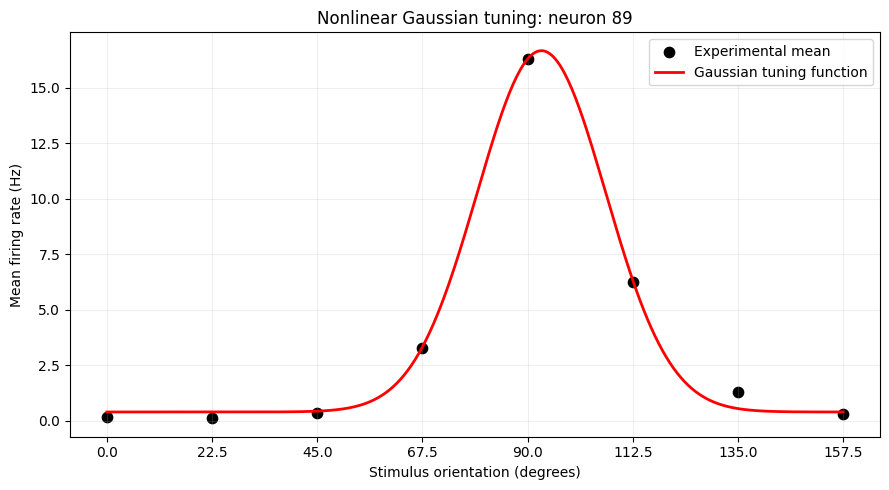

In [14]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ==========================================
# 1. Prepare neuron 89 data
# ==========================================
neuron = 89

angles = (np.asarray(stim).flatten() - 1) * 22.5
spikes = np.asarray(v1_spikes)

duration_sec = spikes.shape[1] / 1000

# Firing rate for each trial
y = spikes[:, :, neuron].sum(axis=1) / duration_sec

# ==========================================
# 2. Calculate mean firing rate per orientation
# ==========================================
unique_angles = np.sort(np.unique(angles))

mean_rates = np.array([
    y[angles == angle].mean()
    for angle in unique_angles
])

# ==========================================
# 3. Define the Gaussian tuning function
# ==========================================
def gaussian_tuning(theta, B, A, mu, sigma):
    return B + A * np.exp(
        -((theta - mu) ** 2) / (2 * sigma ** 2)
    )

# ==========================================
# 4. Fit the function to the observed means
# ==========================================
initial_guess = [
    mean_rates.min(),                 # Baseline B
    mean_rates.max() - mean_rates.min(),  # Amplitude A
    unique_angles[np.argmax(mean_rates)],  # Preferred orientation mu
    30.0                              # Tuning width sigma
]

parameters, covariance = curve_fit(
    gaussian_tuning,
    unique_angles,
    mean_rates,
    p0=initial_guess,
    bounds=(
        [0, 0, 0, 1],
        [np.inf, np.inf, 180, 180]
    ),
    maxfev=20000
)

B, A, mu, sigma = parameters

# ==========================================
# 5. Display estimated parameters
# ==========================================
print(f"Neuron: {neuron}")
print(f"Baseline response (B): {B:.3f} Hz")
print(f"Response amplitude (A): {A:.3f} Hz")
print(f"Preferred orientation (mu): {mu:.3f} degrees")
print(f"Tuning width (sigma): {sigma:.3f} degrees")
print(f"Peak firing rate (B + A): {B + A:.3f} Hz")

# ==========================================
# 6. Plot experimental data and fitted function
# ==========================================
theta_plot = np.linspace(0, 157.5, 400)
fitted_rates = gaussian_tuning(theta_plot, *parameters)

plt.figure(figsize=(9, 5))

# Observed mean firing rates
plt.scatter(
    unique_angles,
    mean_rates,
    color="black",
    s=55,
    label="Experimental mean"
)

# Fitted Gaussian curve
plt.plot(
    theta_plot,
    fitted_rates,
    color="red",
    linewidth=2,
    label="Gaussian tuning function"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (Hz)")
plt.title(f"Nonlinear Gaussian tuning: neuron {neuron}")
plt.xticks(unique_angles)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:
duration_sec

1.28

Neuron: 89
Training trials: 2560
Test trials: 640
Trial duration: 1.280 seconds

GAUSSIAN MODEL PARAMETERS
----------------------------------------
Baseline B:             0.4103 Hz
Amplitude A:            16.3812 Hz
Preferred orientation:  93.0058 degrees
Tuning width sigma:     13.7045 degrees
Peak response B + A:    16.7915 Hz

MODEL PERFORMANCE ON THE SAME TEST TRIALS
---------------------------------------------------------------------------
              Model MSE (Hz²) RMSE (Hz) Test R²
Polynomial degree 7    4.6053    2.1460  0.8263
           Gaussian    4.6566    2.1579  0.8244
Polynomial degree 4   12.6930    3.5627  0.5213
Polynomial degree 3   15.6933    3.9615  0.4081
Polynomial degree 1   25.6614    5.0657  0.0322

Best model by test MSE: Polynomial degree 7


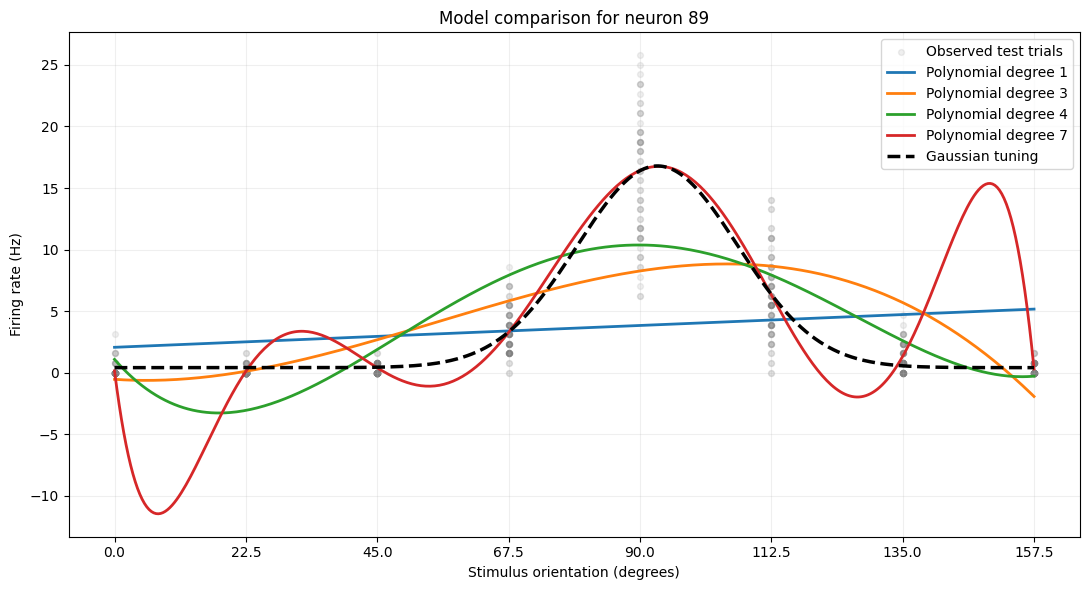

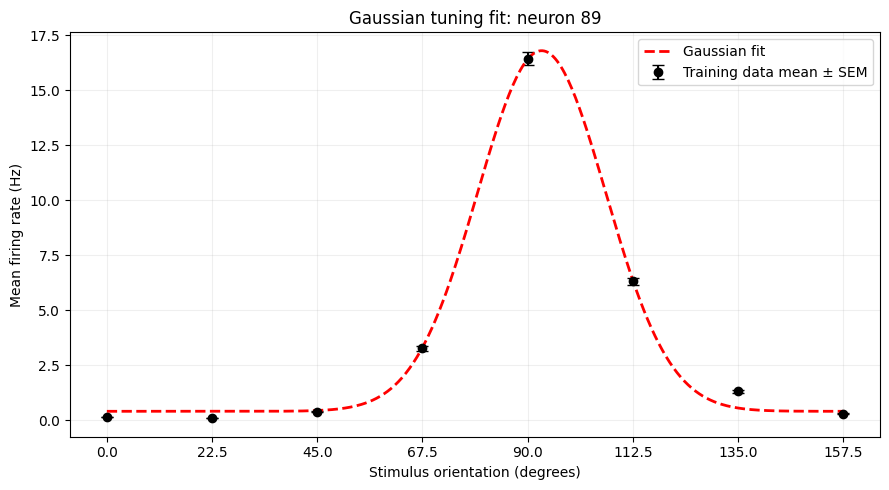

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ==================================================
# 1. PREPARE THE DATA
# ==================================================

neuron = 89

# Convert stimulus labels 1-8 to angles in degrees
angles = (np.asarray(stim).flatten() - 1) * 22.5

# Spike array: (trials, time bins, neurons)
spikes = np.asarray(v1_spikes)

assert len(angles) == spikes.shape[0], (
    "Stimulus labels and spike trials do not match."
)
assert 0 <= neuron < spikes.shape[2], "Invalid neuron index."

# Convert spike counts into firing rates (Hz)
duration_sec = spikes.shape[1] / 1000
y = spikes[:, :, neuron].sum(axis=1) / duration_sec

# ==================================================
# 2. SPLIT THE DATA
# ==================================================

# All models use exactly the same train/test trials
X_train, X_test, y_train, y_test = train_test_split(
    angles.reshape(-1, 1),
    y,
    test_size=0.2,
    random_state=42
)

print(f"Neuron: {neuron}")
print(f"Training trials: {len(X_train)}")
print(f"Test trials: {len(X_test)}")
print(f"Trial duration: {duration_sec:.3f} seconds")

# ==================================================
# 3. FIT POLYNOMIAL MODELS
# Degrees 1, 3, 4 and 7
# ==================================================

degrees = [1, 3, 4, 7]

models = {}
predictions = {}
results = []

# Scale angles for numerical stability
# Scaling is based on the full, known stimulus range
X_train_scaled = (X_train - 78.75) / 78.75
X_test_scaled = (X_test - 78.75) / 78.75

for degree in degrees:

    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train_scaled)
    X_test_poly = poly.transform(X_test_scaled)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred = model.predict(X_test_poly)

    models[f"Polynomial degree {degree}"] = (poly, model)
    predictions[f"Polynomial degree {degree}"] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": f"Polynomial degree {degree}",
        "MSE (Hz²)": mse,
        "RMSE (Hz)": rmse,
        "Test R²": r2
    })

# ==================================================
# 4. DEFINE THE GAUSSIAN TUNING FUNCTION
# ==================================================

def gaussian_tuning(theta, B, A, mu, sigma):
    return B + A * np.exp(
        -((theta - mu) ** 2) / (2 * sigma ** 2)
    )

# ==================================================
# 5. FIT GAUSSIAN USING TRAINING TRIALS ONLY
# ==================================================

train_angles = X_train.ravel()
test_angles = X_test.ravel()

# Obtain training means to initialise the fit
unique_train_angles = np.sort(np.unique(train_angles))

train_means = np.array([
    y_train[train_angles == angle].mean()
    for angle in unique_train_angles
])

baseline_guess = max(0, train_means.min())
amplitude_guess = max(
    train_means.max() - baseline_guess, 0.1
)
preferred_guess = unique_train_angles[
    np.argmax(train_means)
]

initial_guess = [
    baseline_guess,
    amplitude_guess,
    preferred_guess,
    30.0
]

# Fit to individual training trials
gaussian_params, covariance = curve_fit(
    gaussian_tuning,
    train_angles,
    y_train,
    p0=initial_guess,
    bounds=(
        [0, 0, 0, 1],
        [np.inf, np.inf, 180, 180]
    ),
    maxfev=50000
)

B, A, mu, sigma = gaussian_params

# Predict firing rates for held-out trials
y_pred_gaussian = gaussian_tuning(
    test_angles, B, A, mu, sigma
)

predictions["Gaussian"] = y_pred_gaussian

# Evaluate Gaussian on the same test trials
gaussian_mse = mean_squared_error(
    y_test, y_pred_gaussian
)
gaussian_rmse = np.sqrt(gaussian_mse)
gaussian_r2 = r2_score(y_test, y_pred_gaussian)

results.append({
    "Model": "Gaussian",
    "MSE (Hz²)": gaussian_mse,
    "RMSE (Hz)": gaussian_rmse,
    "Test R²": gaussian_r2
})

# ==================================================
# 6. DISPLAY GAUSSIAN PARAMETERS
# ==================================================

print("\nGAUSSIAN MODEL PARAMETERS")
print("-" * 40)
print(f"Baseline B:             {B:.4f} Hz")
print(f"Amplitude A:            {A:.4f} Hz")
print(f"Preferred orientation:  {mu:.4f} degrees")
print(f"Tuning width sigma:     {sigma:.4f} degrees")
print(f"Peak response B + A:    {B + A:.4f} Hz")

# ==================================================
# 7. COMPARE ALL FIVE MODELS
# ==================================================

results_df = pd.DataFrame(results)

# Sort from lowest to highest test MSE
results_df = results_df.sort_values(
    "MSE (Hz²)"
).reset_index(drop=True)

print("\nMODEL PERFORMANCE ON THE SAME TEST TRIALS")
print("-" * 75)
print(results_df.to_string(
    index=False,
    formatters={
        "MSE (Hz²)": "{:.4f}".format,
        "RMSE (Hz)": "{:.4f}".format,
        "Test R²": "{:.4f}".format
    }
))

print("\nBest model by test MSE:",
      results_df.iloc[0]["Model"])

# ==================================================
# 8. PLOT EXPERIMENTAL DATA AND FITTED CURVES
# ==================================================

theta_plot = np.linspace(0, 157.5, 400)
theta_plot_scaled = (
    theta_plot.reshape(-1, 1) - 78.75
) / 78.75

plt.figure(figsize=(11, 6))

# Show held-out trial responses
plt.scatter(
    test_angles,
    y_test,
    alpha=0.12,
    color="gray",
    s=18,
    label="Observed test trials"
)

# Plot polynomial models
for degree in degrees:

    poly, model = models[f"Polynomial degree {degree}"]

    y_curve = model.predict(
        poly.transform(theta_plot_scaled)
    )

    plt.plot(
        theta_plot,
        y_curve,
        linewidth=2,
        label=f"Polynomial degree {degree}"
    )

# Plot Gaussian model
y_gaussian_curve = gaussian_tuning(
    theta_plot, *gaussian_params
)

plt.plot(
    theta_plot,
    y_gaussian_curve,
    color="black",
    linestyle="--",
    linewidth=2.5,
    label="Gaussian tuning"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Firing rate (Hz)")
plt.title(f"Model comparison for neuron {neuron}")
plt.xticks(np.arange(0, 157.5 + 0.1, 22.5))
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ==================================================
# 9. PLOT MEAN EXPERIMENTAL TUNING CURVE
# ==================================================

all_angles = X_train.ravel()
all_y = y_train

unique_angles = np.sort(np.unique(all_angles))

mean_rates = np.array([
    all_y[all_angles == angle].mean()
    for angle in unique_angles
])

sem_rates = np.array([
    all_y[all_angles == angle].std(ddof=1)
    / np.sqrt(np.sum(all_angles == angle))
    for angle in unique_angles
])

plt.figure(figsize=(9, 5))

plt.errorbar(
    unique_angles,
    mean_rates,
    yerr=sem_rates,
    fmt="o",
    capsize=4,
    color="black",
    label="Training data mean ± SEM"
)

plt.plot(
    theta_plot,
    y_gaussian_curve,
    linestyle="--",
    color="red",
    linewidth=2,
    label="Gaussian fit"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (Hz)")
plt.title(f"Gaussian tuning fit: neuron {neuron}")
plt.xticks(unique_angles)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


1. Which model has the lowest MSE?

Answer: Polynomial degree 7 (However, it isn't the best fit)

2. What is the estimated preferred orientation 𝜇?

Preferred orientation:  93.0058 degrees

3. What does 𝜎 tell you about the neuron's tuning?

It depicts how spread (wide or narrow) the features is to the preferred orientation

4. Which parameters of this model have a biological interpretation?


5. Why might this nonlinear model be preferable to a polynomial even if their MSEs are
similar?

From the curve, the non-linear model doesnt seem to have an overfitting problem compared to the 7th degree polynomial


## 3. Von Mises Tuning Model

We will now use a model that explicitly incorporates the circular nature of orientation.

A commonly used model for orientation tuning is the von Mises function:

$$
f(\theta) = B + A\exp\left[\kappa\cos\left(2(\theta-\mu)\right)\right]
$$

where:

- $B$ is the baseline response.
- $A$ controls the amplitude.
- $\mu$ is the preferred orientation.
- $\kappa$ controls the concentration of the tuning curve.

The factor of $2$ accounts for the circular nature of orientation, where $0^\circ$ and $180^\circ$ represent the same orientation.

We will fit the von Mises model to the same neuron's data used in the previous models. We will then evaluate its performance using the mean squared error (MSE) on the test data and compare it with the polynomial and Gaussian models.



## 4. The Circular Nature of Orientation

The models used so far make an important assumption: orientation is treated as an ordinary numerical variable. However, orientation is actually circular.

An orientation of $0^\circ$ is equivalent to $180^\circ$. Therefore, $170^\circ$ and $10^\circ$ are close in orientation space, even though they are far apart numerically.




1. Explain why this creates a problem for the Gaussian model used in Part 3.

2. Why would a Gaussian centered near  0∘  have difficulty representing a tuning curve that extends across the  0∘/180∘  boundary?

3. Why is polynomial regression also problematic for a circular variable?

**4. How would you expect this problem to affect the neuron you selected?**

Von Mises Model Results
Baseline (B): 0.3614 Hz
Amplitude parameter (A): 0.169074
Concentration (kappa): 4.5797
Preferred orientation (mu): 93.14 degrees
Test MSE: 4.6416 Hz²
Test RMSE: 2.1544 Hz
Test R²: 0.8249


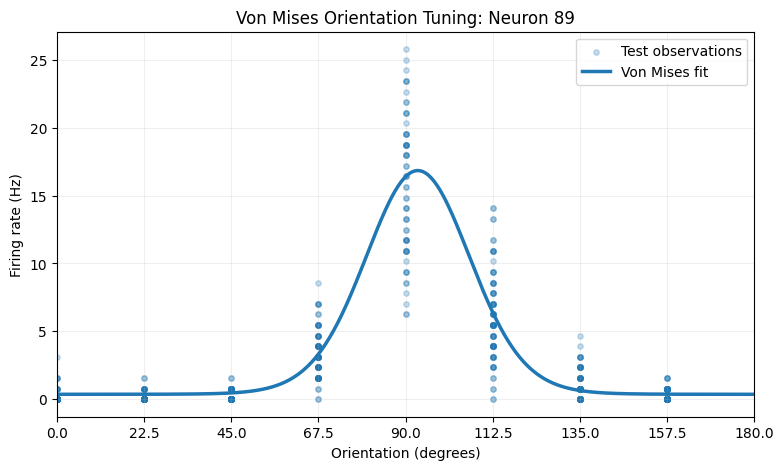

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Use the same data and split as the previous models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Von Mises tuning function
def von_mises(theta, B, A, kappa, mu):
    angle_difference = np.deg2rad(theta - mu)
    return B + A * np.exp(kappa * np.cos(2 * angle_difference))

# Estimate initial parameters from the training data
unique_angles = np.unique(X_train.flatten())

mean_responses = np.array([
    y_train[X_train.flatten() == angle].mean()
    for angle in unique_angles
])

baseline_init = max(0, mean_responses.min())
preferred_init = unique_angles[np.argmax(mean_responses)]
amplitude_init = max(
    (mean_responses.max() - mean_responses.min()) / np.e,
    0.01
)

# Fit the model using training data only
initial_params = [
    baseline_init,
    amplitude_init,
    1.0,
    preferred_init
]

params, _ = curve_fit(
    von_mises,
    X_train.flatten(),
    y_train,
    p0=initial_params,
    bounds=(
        [0, 0, 0.001, 0],
        [np.inf, np.inf, 10, 180]
    ),
    maxfev=50000
)

B, A, kappa, mu = params

# Predict responses on the test data
y_pred = von_mises(X_test.flatten(), B, A, kappa, mu)

# Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Von Mises Model Results")
print(f"Baseline (B): {B:.4f} Hz")
print(f"Amplitude parameter (A): {A:.6f}")
print(f"Concentration (kappa): {kappa:.4f}")
print(f"Preferred orientation (mu): {mu:.2f} degrees")
print(f"Test MSE: {mse:.4f} Hz²")
print(f"Test RMSE: {rmse:.4f} Hz")
print(f"Test R²: {r2:.4f}")

# Plot the model against test observations
theta_plot = np.linspace(0, 180, 500)
fitted_curve = von_mises(theta_plot, B, A, kappa, mu)

plt.figure(figsize=(9, 5))
plt.scatter(
    X_test.flatten(), y_test,
    alpha=0.25, s=15, label="Test observations"
)
plt.plot(
    theta_plot, fitted_curve,
    linewidth=2.5, label="Von Mises fit"
)

plt.xlabel("Orientation (degrees)")
plt.ylabel("Firing rate (Hz)")
plt.title("Von Mises Orientation Tuning: Neuron 89")
plt.xticks(np.arange(0, 181, 22.5))
plt.xlim(0, 180)
plt.legend()
plt.grid(alpha=0.2)
plt.show()


Answer the following questions and use supporting figures:
1. How does the von Mises fit compare with the Gaussian fit?


2. What is the estimated preferred orientation?


3. What does the parameter 𝜅tell you about the neuron's tuning?


4. Why does the equation contain 2(𝜃 − 𝜇)rather than simply (𝜃 − 𝜇)?

5. Does accounting for circularity improve the fit for your selected neuron?


6. Which model would you choose to describe this neuron's orientation tuning, and why?

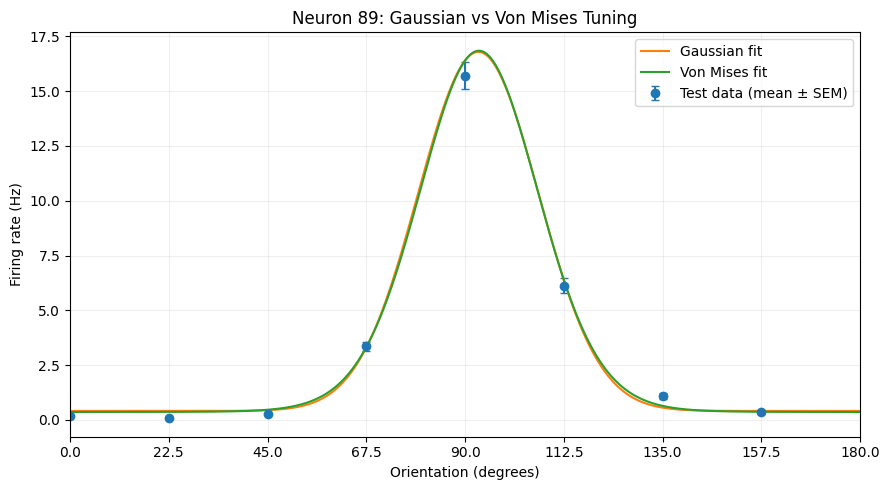

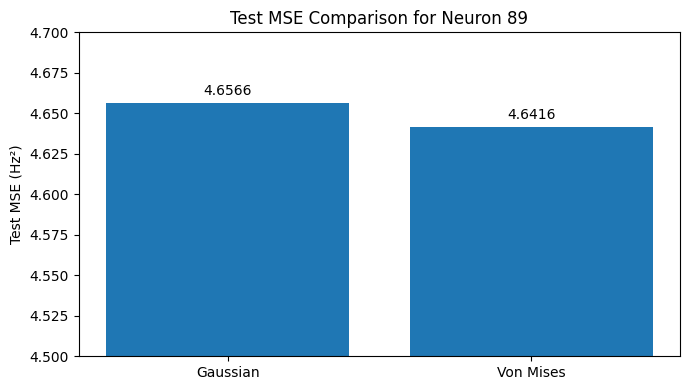

In [16]:

import numpy as np
import matplotlib.pyplot as plt

# Fitted parameters for neuron 89
B_g, A_g, mu_g, sigma_g = 0.4103, 16.3812, 93.0058, 13.7045
B_vm, A_vm, kappa_vm, mu_vm = 0.3614, 0.169074, 4.5797, 93.14

# Tuning functions
def gaussian(theta, B, A, mu, sigma):
    return B + A * np.exp(-((theta - mu)**2) / (2 * sigma**2))

def von_mises(theta, B, A, kappa, mu):
    angle_difference = np.deg2rad(theta - mu)
    return B + A * np.exp(kappa * np.cos(2 * angle_difference))

# Smooth curves
theta_plot = np.linspace(0, 180, 500)

gaussian_fit = gaussian(theta_plot, B_g, A_g, mu_g, sigma_g)
von_mises_fit = von_mises(theta_plot, B_vm, A_vm, kappa_vm, mu_vm)

# Figure 1: Compare tuning curves and observed test responses
angles = np.asarray(X_test).ravel()
responses = np.asarray(y_test).ravel()
unique_angles = np.sort(np.unique(angles))

mean_responses = np.array([
    responses[angles == angle].mean()
    for angle in unique_angles
])

sem_responses = np.array([
    responses[angles == angle].std(ddof=1) /
    np.sqrt(np.sum(angles == angle))
    for angle in unique_angles
])

plt.figure(figsize=(9, 5))

plt.errorbar(
    unique_angles, mean_responses, yerr=sem_responses,
    fmt="o", capsize=3, label="Test data (mean ± SEM)"
)
plt.plot(theta_plot, gaussian_fit, label="Gaussian fit")
plt.plot(theta_plot, von_mises_fit, label="Von Mises fit")

plt.xlabel("Orientation (degrees)")
plt.ylabel("Firing rate (Hz)")
plt.title("Neuron 89: Gaussian vs Von Mises Tuning")
plt.xticks(np.arange(0, 181, 22.5))
plt.xlim(0, 180)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Figure 2: Compare test MSE
models = ["Gaussian", "Von Mises"]
mse_values = [4.6566, 4.6416]

plt.figure(figsize=(7, 4))
bars = plt.bar(models, mse_values)

plt.ylabel("Test MSE (Hz²)")
plt.title("Test MSE Comparison for Neuron 89")
plt.ylim(4.5, 4.7)

for bar, value in zip(bars, mse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.003,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



## 5. Comparing Neurons with Different Noise Levels

Return to the data from Part 1 and select two additional neurons whose responses are substantially noisier than those of the neuron originally selected (neuron 89).

For all three neurons, select three different regression models and fit each model to the data. One of the models must be the Gaussian model.

The models selected for this comparison are:

1. **Linear regression:** Serves as a simple baseline model.
2. **Seventh-order polynomial regression:** Captures nonlinear relationships between stimulus orientation and firing rate.
3. **Gaussian tuning model:** Describes the neuron's orientation tuning using its baseline response, amplitude, preferred orientation, and tuning width.

The models will be evaluated using the same training and test split. Their performance will be compared using the mean squared error (MSE), root mean squared error (RMSE), and test $R^2$.

The aim is to investigate how differences in neuronal response variability affect model performance and how well each model captures orientation tuning across neurons with different noise levels.


Selected neurons:
Neuron 89: within-orientation residual SD = 2.372 Hz
Neuron 102: within-orientation residual SD = 15.054 Hz
Neuron 28: within-orientation residual SD = 12.806 Hz

Model comparison:


,Neuron,Noise SD (Hz),Model,Test MSE (Hz²),Test RMSE (Hz),Test R²
0,28,12.8058,Polynomial degree 7,167.4779,12.9413,0.4999
1,28,12.8058,Gaussian,233.3485,15.2757,0.3032
2,28,12.8058,Linear,297.7532,17.2555,0.1109
3,89,2.3719,Polynomial degree 7,4.6053,2.1460,0.8263
4,89,2.3719,Gaussian,4.6565,2.1579,0.8244
5,89,2.3719,Linear,25.6614,5.0657,0.0322
6,102,15.0536,Polynomial degree 7,232.5433,15.2494,0.5500
7,102,15.0536,Gaussian,254.5584,15.9549,0.5074
8,102,15.0536,Linear,439.2690,20.9587,0.1500


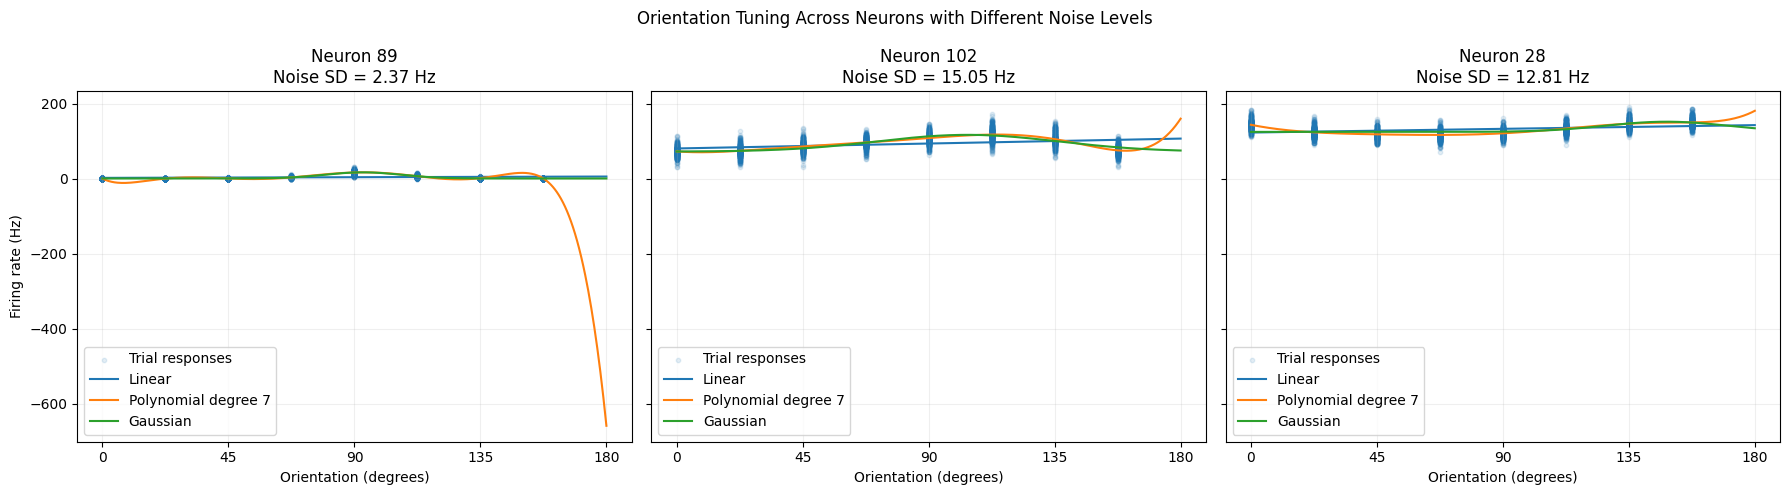

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

# v1_spikes shape: (trials, time bins, neurons)
# stim contains stimulus labels from 1 to 8

stim_labels = np.asarray(stim).flatten()
angles = (stim_labels - 1) * 22.5

# Convert spike counts into average firing rate per trial (Hz)
# Assumes each trial lasts 1.280 seconds
duration_sec = 1.280

firing_rates = v1_spikes.sum(axis=1) / duration_sec
# Shape: (3200 trials, 111 neurons)

original_neuron = 89  # Assumes 89 is the Python array index

# --------------------------------------------------
# 2. Identify two noisier neurons
# --------------------------------------------------

# Measure trial-to-trial variability after removing
# each neuron's mean response to each orientation.

noise_scores = []

for neuron in range(firing_rates.shape[1]):
    responses = firing_rates[:, neuron]

    residuals = np.zeros_like(responses, dtype=float)

    for angle in np.unique(angles):
        mask = angles == angle
        residuals[mask] = (
            responses[mask] - responses[mask].mean()
        )

    noise_sd = np.std(residuals, ddof=1)
    noise_scores.append(noise_sd)

noise_scores = np.asarray(noise_scores)

# Rank neurons from most to least variable,
# excluding the original neuron.
ranked_neurons = np.argsort(noise_scores)[::-1]
ranked_neurons = ranked_neurons[
    ranked_neurons != original_neuron
]

noisy_neurons = ranked_neurons[:2]

selected_neurons = [
    original_neuron,
    int(noisy_neurons[0]),
    int(noisy_neurons[1])
]

print("Selected neurons:")
for neuron in selected_neurons:
    print(
        f"Neuron {neuron}: "
        f"within-orientation residual SD = "
        f"{noise_scores[neuron]:.3f} Hz"
    )

# --------------------------------------------------
# 3. Define the Gaussian tuning function
# --------------------------------------------------

def gaussian(theta, B, A, mu, sigma):
    return B + A * np.exp(
        -((theta - mu) ** 2) / (2 * sigma ** 2)
    )

# --------------------------------------------------
# 4. Fit three models for each neuron
# --------------------------------------------------

results = []
fitted_curves = {}

theta_plot = np.linspace(0, 180, 500)

for neuron in selected_neurons:

    X = angles.reshape(-1, 1)
    y = firing_rates[:, neuron]

    # Same 80/20 split for each neuron
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    x_train = X_train.ravel()
    x_test = X_test.ravel()

    # Scale angles for stable polynomial calculations
    x_train_scaled = (x_train - 78.75) / 78.75
    x_test_scaled = (x_test - 78.75) / 78.75
    theta_plot_scaled = (theta_plot - 78.75) / 78.75

    # Model 1: Linear regression
    linear_model = LinearRegression()
    linear_model.fit(
        x_train_scaled.reshape(-1, 1), y_train
    )
    pred_linear = linear_model.predict(
        x_test_scaled.reshape(-1, 1)
    )

    # Model 2: 7th-order polynomial regression
    poly_model = make_pipeline(
        PolynomialFeatures(degree=7, include_bias=False),
        LinearRegression()
    )
    poly_model.fit(
        x_train_scaled.reshape(-1, 1), y_train
    )
    pred_poly = poly_model.predict(
        x_test_scaled.reshape(-1, 1)
    )

    # Model 3: Gaussian tuning curve
    unique_angles = np.unique(x_train)
    mean_responses = np.array([
        y_train[x_train == angle].mean()
        for angle in unique_angles
    ])

    baseline_init = max(0, mean_responses.min())
    preferred_init = unique_angles[
        np.argmax(mean_responses)
    ]
    amplitude_init = max(
        mean_responses.max() - mean_responses.min(),
        0.1
    )

    initial_params = [
        baseline_init, amplitude_init,
        preferred_init, 20.0
    ]

    params, _ = curve_fit(
        gaussian,
        x_train,
        y_train,
        p0=initial_params,
        bounds=(
            [0, 0, 0, 1],
            [np.inf, np.inf, 180, 180]
        ),
        maxfev=50000
    )

    pred_gaussian = gaussian(x_test, *params)

    # Evaluate models on the same test trials
    predictions = {
        "Linear": pred_linear,
        "Polynomial degree 7": pred_poly,
        "Gaussian": pred_gaussian
    }

    for model_name, prediction in predictions.items():
        results.append({
            "Neuron": neuron,
            "Noise SD (Hz)": noise_scores[neuron],
            "Model": model_name,
            "Test MSE (Hz²)": mean_squared_error(
                y_test, prediction
            ),
            "Test RMSE (Hz)": np.sqrt(
                mean_squared_error(y_test, prediction)
            ),
            "Test R²": r2_score(y_test, prediction)
        })

    # Save curves for plotting
    fitted_curves[neuron] = {
        "Linear": linear_model.predict(
            theta_plot_scaled.reshape(-1, 1)
        ),
        "Polynomial degree 7": poly_model.predict(
            theta_plot_scaled.reshape(-1, 1)
        ),
        "Gaussian": gaussian(theta_plot, *params),
        "Gaussian parameters": params
    }

# --------------------------------------------------
# 5. Display the comparison table
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\nModel comparison:")
display(
    results_df.round(4).sort_values(
        ["Neuron", "Test MSE (Hz²)"]
    ).reset_index(drop=True)
)

# --------------------------------------------------
# 6. Plot the three models for each neuron
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), sharey=True
)

for ax, neuron in zip(axes, selected_neurons):

    ax.scatter(
        angles,
        firing_rates[:, neuron],
        alpha=0.12,
        s=10,
        label="Trial responses"
    )

    curves = fitted_curves[neuron]

    ax.plot(
        theta_plot, curves["Linear"],
        label="Linear"
    )
    ax.plot(
        theta_plot, curves["Polynomial degree 7"],
        label="Polynomial degree 7"
    )
    ax.plot(
        theta_plot, curves["Gaussian"],
        label="Gaussian"
    )

    ax.set_title(
        f"Neuron {neuron}\n"
        f"Noise SD = {noise_scores[neuron]:.2f} Hz"
    )
    ax.set_xlabel("Orientation (degrees)")
    ax.set_xticks(np.arange(0, 181, 45))
    ax.grid(alpha=0.2)
    ax.legend()

axes[0].set_ylabel("Firing rate (Hz)")
fig.suptitle(
    "Orientation Tuning Across Neurons with Different Noise Levels"
)
plt.tight_layout()
plt.show()


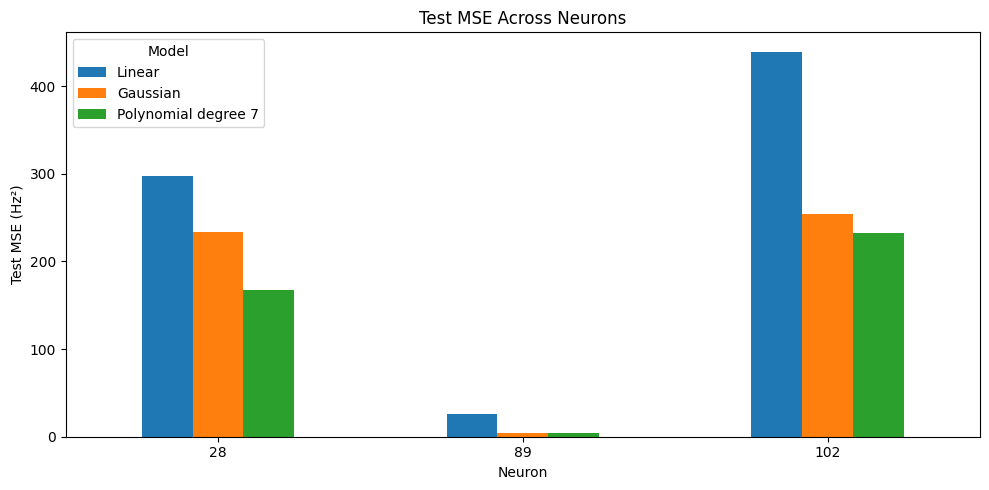

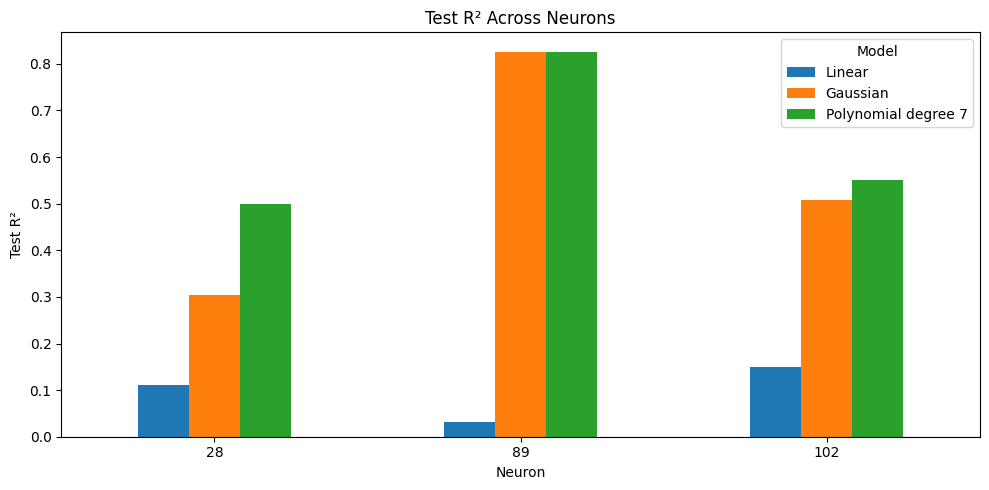

In [18]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results = pd.DataFrame({
    "Neuron": [28, 28, 28, 89, 89, 89, 102, 102, 102],
    "Noise SD (Hz)": [
        12.8058, 12.8058, 12.8058,
        2.3719, 2.3719, 2.3719,
        15.0536, 15.0536, 15.0536
    ],
    "Model": [
        "Polynomial degree 7", "Gaussian", "Linear",
        "Polynomial degree 7", "Gaussian", "Linear",
        "Polynomial degree 7", "Gaussian", "Linear"
    ],
    "Test MSE (Hz²)": [
        167.4779, 233.3485, 297.7532,
        4.6053, 4.6565, 25.6614,
        232.5433, 254.5584, 439.2690
    ],
    "Test R²": [
        0.4999, 0.3032, 0.1109,
        0.8263, 0.8244, 0.0322,
        0.5500, 0.5074, 0.1500
    ]
})

# Figure 1: Test MSE
mse_pivot = results.pivot(
    index="Neuron",
    columns="Model",
    values="Test MSE (Hz²)"
)

mse_pivot = mse_pivot[
    ["Linear", "Gaussian", "Polynomial degree 7"]
]

ax = mse_pivot.plot(
    kind="bar", figsize=(10, 5)
)
ax.set_title("Test MSE Across Neurons")
ax.set_xlabel("Neuron")
ax.set_ylabel("Test MSE (Hz²)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
plt.tight_layout()
plt.show()

# Figure 2: Test R²
r2_pivot = results.pivot(
    index="Neuron",
    columns="Model",
    values="Test R²"
)

r2_pivot = r2_pivot[
    ["Linear", "Gaussian", "Polynomial degree 7"]
]

ax = r2_pivot.plot(
    kind="bar", figsize=(10, 5)
)
ax.set_title("Test R² Across Neurons")
ax.set_xlabel("Neuron")
ax.set_ylabel("Test R²")
ax.axhline(0, linewidth=0.8)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
plt.tight_layout()
plt.show()
